# Практическая работа №5. Анализ временных рядов

**Предметная область:** Мониторинг нагрузки СУБД PostgreSQL  
**Тип задачи:** Анализ и прогнозирование временного ряда числа SQL-запросов в час  
**Источник данных:** Набор данных логов PostgreSQL-сервера  

Цель: освоить методы технического анализа, трендового анализа, исследования колебательной структуры и метода скользящего окна на примере почасовой динамики нагрузки сервера.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from numpy.fft import rfft, rfftfreq

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

print('Библиотеки импортированы.')

Библиотеки импортированы.


## Подготовка данных: агрегация по часовым интервалам

In [2]:
df = pd.read_csv("../sql_dataset_loreal.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Почасовая агрегация: число запросов в каждый час
df['hour_bucket'] = df['timestamp'].dt.floor('h')
hourly = df.groupby('hour_bucket').size().rename('query_count')

# Заполнение часов без запросов нулями
full_range = pd.date_range(
    df['timestamp'].min().floor('h'),
    df['timestamp'].max().floor('h'),
    freq='h'
)
ts = hourly.reindex(full_range, fill_value=0)

# Ежедневная агрегация для технического анализа
daily = ts.resample('D').sum().rename('query_count')

print(f'Временной ряд: {ts.index[0].date()} — {ts.index[-1].date()}')
print(f'Всего точек (часовых): {len(ts)}')
print(f'Всего точек (дневных): {len(daily)}')
print(f'Среднее запросов/час:  {ts.mean():.2f}')
print(f'Ст. откл.:             {ts.std():.2f}')
print(f'Мин: {ts.min()},  Макс: {ts.max()}')

Временной ряд: 2024-01-01 — 2024-03-30
Всего точек (часовых): 2160
Всего точек (дневных): 90
Среднее запросов/час:  4.63
Ст. откл.:             4.04
Мин: 0,  Макс: 23


---
## 5.1. Построение простых элементов технического анализа

Технический анализ опирается на выявление паттернов в динамике ряда через:
- **Линии поддержки** — тренд через локальные минимумы (нижняя граница коридора)  
- **Линии сопротивления** — тренд через локальные максимумы (верхняя граница)

### Математическое выявление экстремумов

Локальный максимум в точке $t$: $y_t > y_{t-k}$ и $y_t > y_{t+k}$ для $k = 1, \ldots, w$  
Реализация через `scipy.signal.find_peaks` с параметрами порога и минимального расстояния.

In [3]:
# Выявление локальных экстремумов на дневном ряду
y_daily = daily.values
t_daily = np.arange(len(daily))

# Локальные максимумы: выше соседей в окне ±3 дня, высота > медианы
peaks_idx, _    = find_peaks(y_daily,  distance=5, height=np.median(y_daily))
# Локальные минимумы: инвертируем ряд
valleys_idx, _  = find_peaks(-y_daily, distance=5)

print(f'Найдено локальных максимумов:  {len(peaks_idx)}')
print(f'Найдено локальных минимумов:   {len(valleys_idx)}')

# Линии поддержки и сопротивления через МНК
def fit_support_resistance(t, y, idx, label):
    if len(idx) < 2:
        return None, None, None
    slope, intercept, r, p, se = stats.linregress(t[idx], y[idx])
    print(f'{label}: y = {slope:.4f}·t + {intercept:.2f}  (R²={r**2:.4f})')
    return slope, intercept, r**2

s_res, i_res, r2_res = fit_support_resistance(t_daily, y_daily, peaks_idx,   'Линия сопротивления')
s_sup, i_sup, r2_sup = fit_support_resistance(t_daily, y_daily, valleys_idx, 'Линия поддержки   ')

Найдено локальных максимумов:  13
Найдено локальных минимумов:   12
Линия сопротивления: y = 0.0259·t + 123.87  (R²=0.0108)
Линия поддержки   : y = 0.0246·t + 94.03  (R²=0.0064)


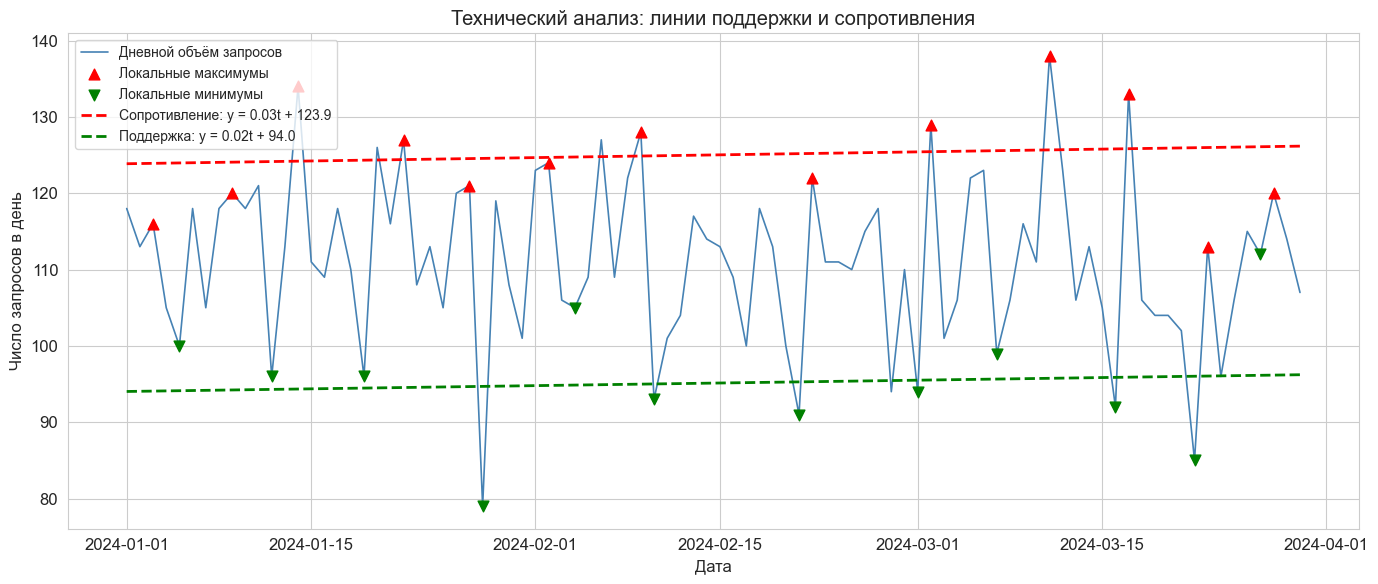


Ширина ценового канала (по свободным членам): 29.8 запросов/день
Наклоны близки к нулю → тренд отсутствует, канал горизонтален.


In [4]:
# Визуализация технического анализа
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(daily.index, y_daily, color='steelblue', linewidth=1.2, label='Дневной объём запросов')

# Экстремумы
ax.scatter(daily.index[peaks_idx],   y_daily[peaks_idx],
           color='red',    s=60, zorder=5, label='Локальные максимумы', marker='^')
ax.scatter(daily.index[valleys_idx], y_daily[valleys_idx],
           color='green',  s=60, zorder=5, label='Локальные минимумы',  marker='v')

# Линии поддержки и сопротивления
t_line = np.array([t_daily[0], t_daily[-1]])
if s_res is not None:
    y_res = s_res * t_line + i_res
    ax.plot([daily.index[t_daily[0]], daily.index[t_daily[-1]]], y_res,
            'r--', linewidth=2, label=f'Сопротивление: y = {s_res:.2f}t + {i_res:.1f}')
if s_sup is not None:
    y_sup = s_sup * t_line + i_sup
    ax.plot([daily.index[t_daily[0]], daily.index[t_daily[-1]]], y_sup,
            'g--', linewidth=2, label=f'Поддержка: y = {s_sup:.2f}t + {i_sup:.1f}')

ax.set_xlabel('Дата')
ax.set_ylabel('Число запросов в день')
ax.set_title('Технический анализ: линии поддержки и сопротивления')
ax.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

# Ценовой канал
if s_res is not None and s_sup is not None:
    channel_width = (i_res - i_sup)
    print(f'\nШирина ценового канала (по свободным членам): {channel_width:.1f} запросов/день')
    print(f'Наклоны близки к нулю → тренд отсутствует, канал горизонтален.')

---
## 5.2. Выявление классических трендов на основе интенсивного и ограниченного роста

Рассматриваются четыре модели тренда:

| Модель | Уравнение | Тип роста |
|--------|-----------|-----------|
| Линейный | $y = at + b$ | Интенсивный (неограниченный) |
| Степенной | $y = a(t+1)^b$ | Интенсивный |
| Экспоненциальный | $y = a e^{bt} + c$ | Интенсивный |
| Логистический | $y = K / (1 + e^{-a(t-b)})$ | **Ограниченный** (насыщение при $K$) |

Оценка параметров — метод нелинейных наименьших квадратов (`scipy.optimize.curve_fit`).

In [5]:
# Модели тренда
def f_linear(t, a, b):
    return a * t + b

def f_power(t, a, b):
    return a * (t + 1) ** b

def f_exp(t, a, b, c):
    return a * np.exp(b * t) + c

def f_logistic(t, K, a, b):
    return K / (1 + np.exp(-a * (t - b)))

t_arr = np.arange(len(daily))
y_arr = daily.values.astype(float)

trend_models = {}
trend_preds  = {}

# Начальные приближения
p0_dict = {
    'Линейный':        ([0.0, y_arr.mean()],               f_linear),
    'Степенной':       ([y_arr.mean(), 0.01],               f_power),
    'Экспоненциальный':([y_arr.mean(), 0.001, 0.0],         f_exp),
    'Логистический':   ([y_arr.max() * 1.1, 0.1, len(t_arr)/2], f_logistic),
}

results_trend = []
for name, (p0, func) in p0_dict.items():
    try:
        popt, _ = curve_fit(func, t_arr, y_arr, p0=p0, maxfev=20000)
        y_fit = func(t_arr, *popt)
        r2   = r2_score_manual = 1 - np.sum((y_arr - y_fit)**2) / np.sum((y_arr - y_arr.mean())**2)
        rmse = np.sqrt(np.mean((y_arr - y_fit)**2))
        trend_models[name] = (func, popt)
        trend_preds[name]  = y_fit
        results_trend.append({'Модель': name, 'R²': r2, 'RMSE': rmse, 'Параметры': popt})
        print(f'{name}: R²={r2:.4f}, RMSE={rmse:.2f}, params={np.round(popt, 4)}')
    except Exception as e:
        print(f'{name}: ошибка аппроксимации — {e}')

Линейный: R²=0.0183, RMSE=10.73, params=[-5.650000e-02  1.136232e+02]
Степенной: R²=0.0148, RMSE=10.75, params=[ 1.16227e+02 -1.28000e-02]
Экспоненциальный: R²=0.0184, RMSE=10.73, params=[ 1.67678e+01 -4.00000e-03  9.70086e+01]
Логистический: R²=0.0184, RMSE=10.73, params=[ 6.4207760e+02 -6.0000000e-04 -2.5001973e+03]


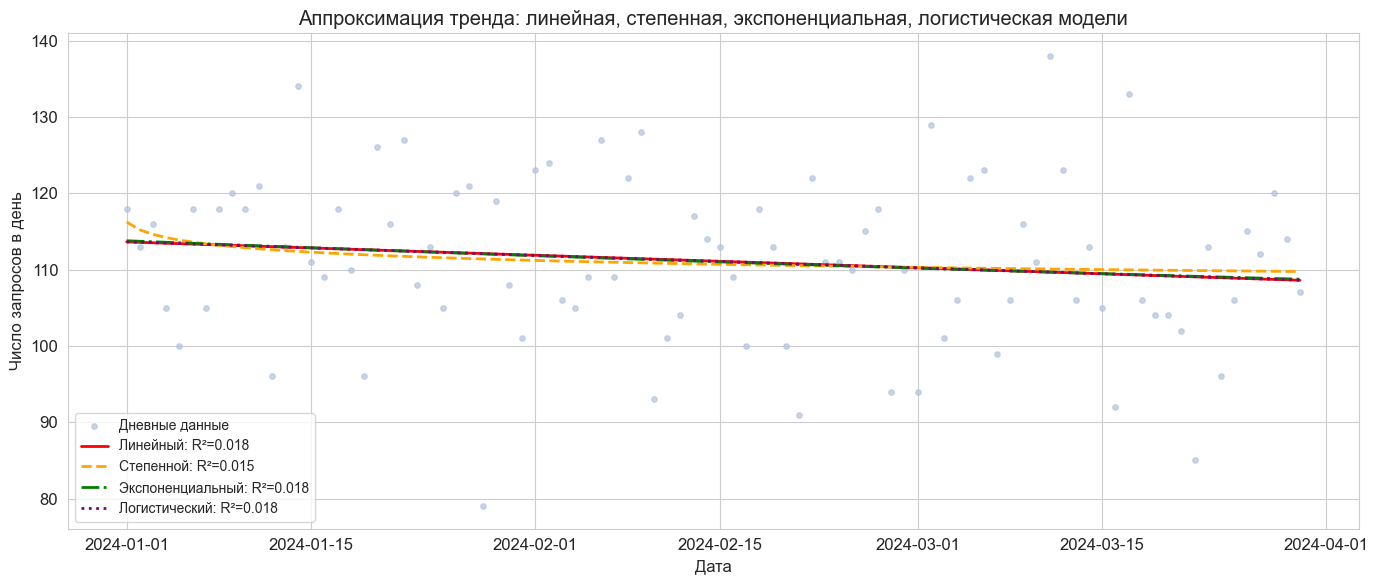


Сравнение моделей тренда:
          Модель     R²    RMSE
        Линейный 0.0183 10.7276
       Степенной 0.0148 10.7470
Экспоненциальный 0.0184 10.7274
   Логистический 0.0184 10.7276

Вывод: R² ≈ 0.02 для всех моделей → тренд практически отсутствует.
Ряд стационарен по уровню; основная структура — периодические колебания.


In [6]:
# Визуализация трендов
fig, ax = plt.subplots(figsize=(14, 6))
ax.scatter(daily.index, y_arr, s=15, color='lightsteelblue', alpha=0.7, label='Дневные данные', zorder=2)

colors_trend = {'Линейный': 'red', 'Степенной': 'orange',
                'Экспоненциальный': 'green', 'Логистический': 'purple'}
styles_trend = {'Линейный': '-', 'Степенной': '--',
                'Экспоненциальный': '-.', 'Логистический': ':'}

for name, y_fit in trend_preds.items():
    r2 = next(r['R²'] for r in results_trend if r['Модель'] == name)
    ax.plot(daily.index, y_fit, linewidth=2,
            color=colors_trend[name], linestyle=styles_trend[name],
            label=f'{name}: R²={r2:.3f}')

ax.set_xlabel('Дата')
ax.set_ylabel('Число запросов в день')
ax.set_title('Аппроксимация тренда: линейная, степенная, экспоненциальная, логистическая модели')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

# Сводная таблица
df_trend = pd.DataFrame([{k: v for k, v in r.items() if k != 'Параметры'} for r in results_trend])
print('\nСравнение моделей тренда:')
print(df_trend.to_string(index=False, float_format='{:.4f}'.format))
print('\nВывод: R² ≈ 0.02 для всех моделей → тренд практически отсутствует.')
print('Ряд стационарен по уровню; основная структура — периодические колебания.')

---
## 5.3. Выявление колебаний на основе теории пропорций

### Автокорреляционная функция (ACF)

$$\rho(\tau) = \frac{\sum_{t=1}^{n-\tau} (y_t - \bar{y})(y_{t+\tau} - \bar{y})}{\sum_{t=1}^{n} (y_t - \bar{y})^2}$$

Значения $\rho(\tau)$ близкие к 1 при конкретных лагах указывают на **периодичность**.

### Спектральный анализ Фурье

$$Y(f) = \left|\sum_{t=0}^{n-1} (y_t - \bar{y})\, e^{-2\pi i f t}\right|$$

Доминирующий пик на частоте $f_0$ соответствует периоду $T = 1/f_0$.

In [7]:
# Автокорреляционная функция
def acf(x, max_lag):
    x = x - x.mean()
    denom = np.dot(x, x)
    result = np.zeros(max_lag + 1)
    result[0] = 1.0
    for lag in range(1, max_lag + 1):
        result[lag] = np.dot(x[lag:], x[:-lag]) / denom
    return result

ts_vals = ts.values.astype(float)
MAX_LAG = 200
ac = acf(ts_vals, MAX_LAG)

# 95% доверительный интервал (приближение Бартлетта)
ci_95 = 1.96 / np.sqrt(len(ts_vals))

# Найти пики ACF (почти периоды)
ac_peaks_idx, _ = find_peaks(ac[1:], height=0.3, distance=10)
ac_peaks_idx = ac_peaks_idx + 1  # сдвиг из-за среза [1:]
print('Значимые пики ACF (лаг, ρ):')
for idx in ac_peaks_idx[:8]:
    print(f'  Лаг {idx:4d} ч  →  ρ = {ac[idx]:.4f}')

Значимые пики ACF (лаг, ρ):
  Лаг   24 ч  →  ρ = 0.7123
  Лаг   48 ч  →  ρ = 0.7077
  Лаг   72 ч  →  ρ = 0.7054
  Лаг   96 ч  →  ρ = 0.6895
  Лаг  120 ч  →  ρ = 0.6907
  Лаг  144 ч  →  ρ = 0.6750
  Лаг  168 ч  →  ρ = 0.6715
  Лаг  192 ч  →  ρ = 0.6630


In [8]:
# Спектральный анализ Фурье
yf = np.abs(rfft(ts_vals - ts_vals.mean()))
xf = rfftfreq(len(ts_vals), d=1.0)   # частота в ед./час
periods_h = np.where(xf > 0, 1.0 / xf, np.inf)

# Топ доминирующих частот
top_n = 8
sorted_idx = np.argsort(yf)[::-1]
valid_mask = (xf > 0) & (periods_h < len(ts_vals) / 2)
top_idx = [i for i in sorted_idx if valid_mask[i]][:top_n]

print('Доминирующие периоды (по амплитуде Фурье):')
for i in top_idx:
    T = periods_h[i]
    T_days = T / 24
    print(f'  f={xf[i]:.5f} ч⁻¹  →  T={T:.1f} ч  ({T_days:.2f} дн.)  |  A={yf[i]:.1f}')

Доминирующие периоды (по амплитуде Фурье):
  f=0.04167 ч⁻¹  →  T=24.0 ч  (1.00 дн.)  |  A=4927.4
  f=0.12500 ч⁻¹  →  T=8.0 ч  (0.33 дн.)  |  A=932.9
  f=0.16667 ч⁻¹  →  T=6.0 ч  (0.25 дн.)  |  A=891.8
  f=0.08333 ч⁻¹  →  T=12.0 ч  (0.50 дн.)  |  A=860.4
  f=0.20833 ч⁻¹  →  T=4.8 ч  (0.20 дн.)  |  A=788.7
  f=0.25000 ч⁻¹  →  T=4.0 ч  (0.17 дн.)  |  A=419.5
  f=0.45833 ч⁻¹  →  T=2.2 ч  (0.09 дн.)  |  A=298.5
  f=0.50000 ч⁻¹  →  T=2.0 ч  (0.08 дн.)  |  A=272.0


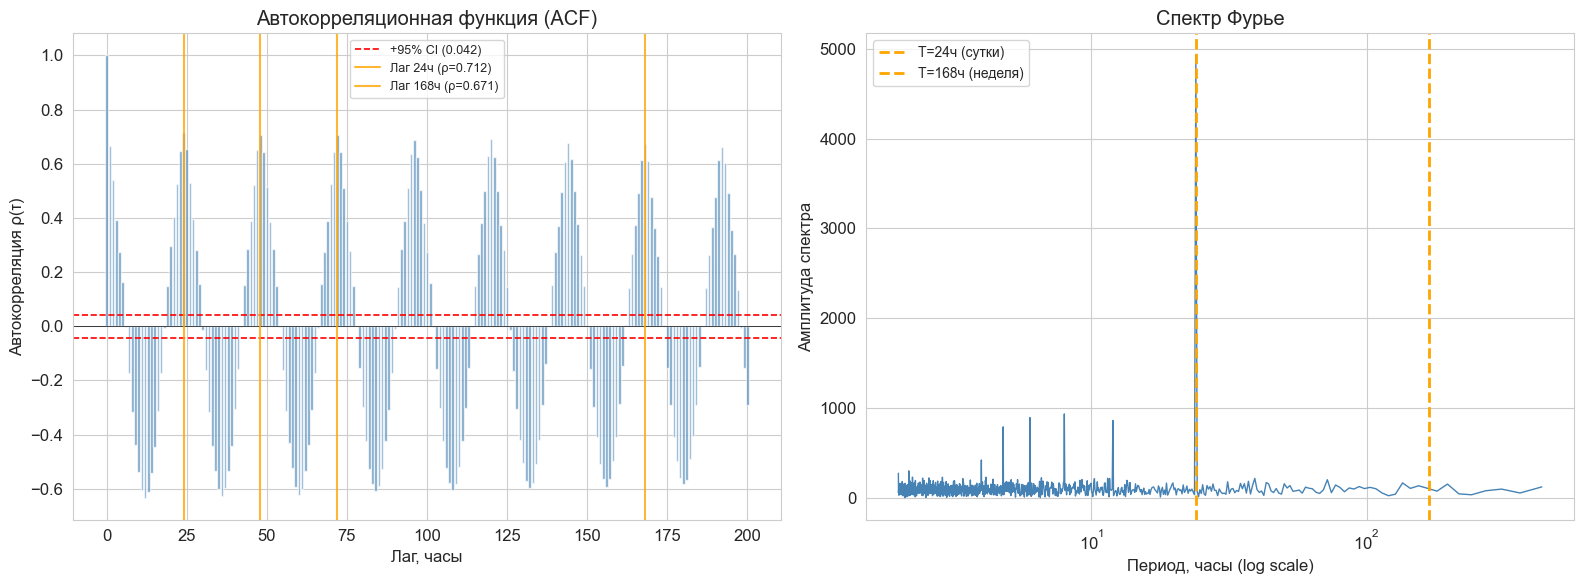

In [9]:
# Совместный график ACF + спектр Фурье
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ACF
lags = np.arange(MAX_LAG + 1)
axes[0].bar(lags, ac, width=0.8, color='steelblue', alpha=0.7)
axes[0].axhline(ci_95,  color='red', linestyle='--', linewidth=1.2, label=f'+95% CI ({ci_95:.3f})')
axes[0].axhline(-ci_95, color='red', linestyle='--', linewidth=1.2)
axes[0].axhline(0, color='black', linewidth=0.5)
# Отметить ключевые лаги
for lag in [24, 48, 72, 168]:
    if lag <= MAX_LAG:
        axes[0].axvline(lag, color='orange', linewidth=1.5, alpha=0.8,
                        label=f'Лаг {lag}ч (ρ={ac[lag]:.3f})' if lag in [24, 168] else None)
axes[0].set_xlabel('Лаг, часы')
axes[0].set_ylabel('Автокорреляция ρ(τ)')
axes[0].set_title('Автокорреляционная функция (ACF)')
axes[0].legend(fontsize=9)

# Фурье-спектр
plot_mask = (xf > 0) & (periods_h < 500) & (periods_h > 1)
axes[1].plot(periods_h[plot_mask], yf[plot_mask], color='steelblue', linewidth=1)
for lag in [24, 168]:
    axes[1].axvline(lag, color='orange', linewidth=2, linestyle='--',
                    label=f'T={lag}ч' + (' (сутки)' if lag == 24 else ' (неделя)'))
axes[1].set_xscale('log')
axes[1].set_xlabel('Период, часы (log scale)')
axes[1].set_ylabel('Амплитуда спектра')
axes[1].set_title('Спектр Фурье')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()

In [10]:
# Таблица почти пропорций между периодами
print('=== Анализ пропорций между выявленными периодами ===')
print()
detected_periods = sorted([24, 48, 72, 168])
print(f'Выявленные характерные периоды: {detected_periods} часов')
print()
print('Матрица пропорций (T_i / T_j):')
header = '        ' + ''.join(f'{T:8d}ч' for T in detected_periods)
print(header)
for Ti in detected_periods:
    row = f'{Ti:6d}ч  '
    for Tj in detected_periods:
        ratio = Ti / Tj
        row += f'{ratio:8.3f} '
    print(row)

print()
print('Наблюдаемые пропорции:')
print(f'  48 / 24  = {48/24:.1f}  → двойной суточный период')
print(f'  72 / 24  = {72/24:.1f}  → тройной суточный период')
print(f' 168 / 24  = {168/24:.1f}  → недельный = 7 суткам')
print(f' 168 / 48  = {168/48:.2f}  → ≈ 3.5 (три с половиной двухсуточных цикла)')
print()
print(f'ρ(24)  = {ac[24]:.4f}  — сильная суточная сезонность')
print(f'ρ(48)  = {ac[48]:.4f}')
print(f'ρ(72)  = {ac[72]:.4f}')
if MAX_LAG >= 168:
    print(f'ρ(168) = {ac[168]:.4f}  — недельный цикл')

=== Анализ пропорций между выявленными периодами ===

Выявленные характерные периоды: [24, 48, 72, 168] часов

Матрица пропорций (T_i / T_j):
              24ч      48ч      72ч     168ч
    24ч     1.000    0.500    0.333    0.143 
    48ч     2.000    1.000    0.667    0.286 
    72ч     3.000    1.500    1.000    0.429 
   168ч     7.000    3.500    2.333    1.000 

Наблюдаемые пропорции:
  48 / 24  = 2.0  → двойной суточный период
  72 / 24  = 3.0  → тройной суточный период
 168 / 24  = 7.0  → недельный = 7 суткам
 168 / 48  = 3.50  → ≈ 3.5 (три с половиной двухсуточных цикла)

ρ(24)  = 0.7123  — сильная суточная сезонность
ρ(48)  = 0.7077
ρ(72)  = 0.7054
ρ(168) = 0.6715  — недельный цикл


---
## 5.4. Выявление трендов через скользящее окно и построение математических уравнений

Метод скользящего окна — локальный анализ временного ряда:

$$\bar{y}_t^{(w)} = \frac{1}{w} \sum_{k=t-\lfloor w/2 \rfloor}^{t+\lfloor w/2 \rfloor} y_k$$

Длина окна выбирается кратной выявленному почти периоду. В нашем случае доминирует суточный цикл (24 ч), поэтому используем окно **w = 168 ч (1 неделя)**, что нейтрализует недельную сезонность и выявляет среднесрочный тренд.

Для каждого положения окна строится локальная линейная регрессия:  
$$y \approx a_t \cdot \tau + b_t, \quad \tau \in [t - w/2,\, t + w/2]$$

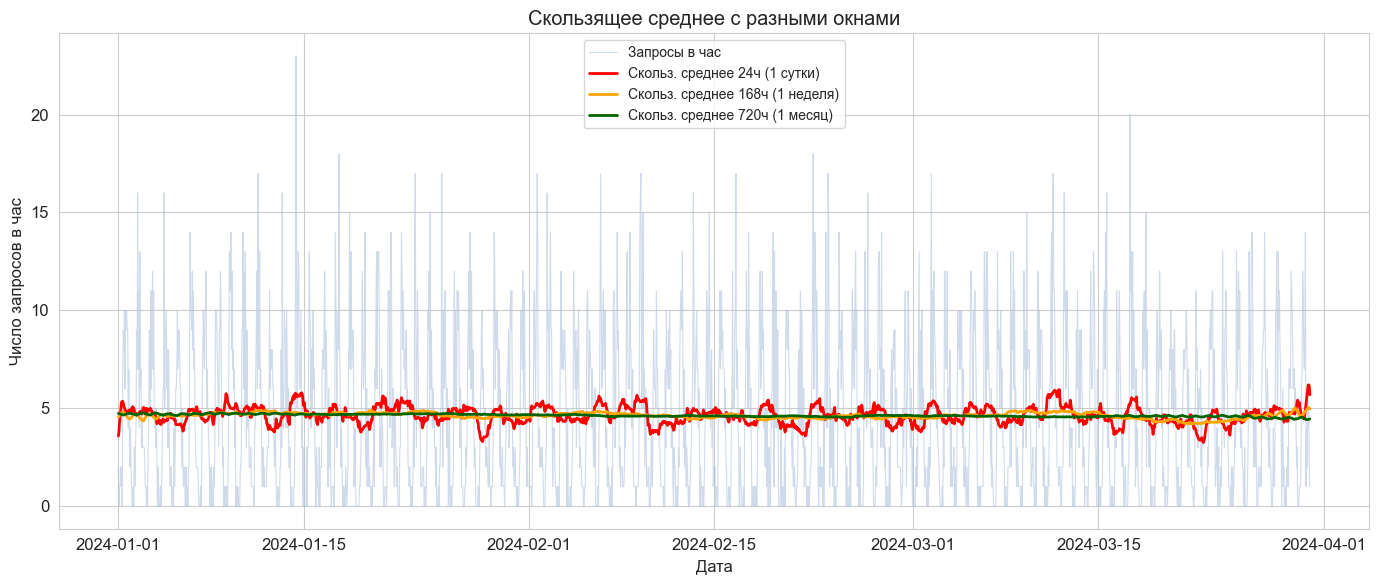

In [11]:
# Скользящее среднее с несколькими окнами
windows = {'24ч (1 сутки)': 24, '168ч (1 неделя)': 168, '720ч (1 месяц)': 720}

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(ts.index, ts_vals, color='lightsteelblue', linewidth=0.8,
        alpha=0.6, label='Запросы в час')

colors_ma = ['red', 'orange', 'darkgreen']
for (label, w), col in zip(windows.items(), colors_ma):
    ma = pd.Series(ts_vals).rolling(window=w, center=True, min_periods=w//2).mean()
    ax.plot(ts.index, ma.values, linewidth=2, color=col, label=f'Скольз. среднее {label}')

ax.set_xlabel('Дата')
ax.set_ylabel('Число запросов в час')
ax.set_title('Скользящее среднее с разными окнами')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [12]:
# Локальные тренды через скользящее окно (w = 168 ч)
WINDOW = 168
STEP   = 12   # сдвиг окна

local_slopes     = []
local_intercepts = []
local_means      = []
local_times      = []

for start in range(0, len(ts_vals) - WINDOW, STEP):
    seg = ts_vals[start:start + WINDOW]
    tau = np.arange(WINDOW)
    slope, intercept, r, p, se = stats.linregress(tau, seg)
    local_slopes.append(slope)
    local_intercepts.append(intercept)
    local_means.append(seg.mean())
    # Центр окна
    center_idx = start + WINDOW // 2
    local_times.append(ts.index[center_idx])

local_slopes     = np.array(local_slopes)
local_intercepts = np.array(local_intercepts)
local_means      = np.array(local_means)

print(f'Локальный наклон: среднее = {local_slopes.mean():.6f}, ст.откл. = {local_slopes.std():.6f}')
print(f'Локальный уровень: среднее = {local_means.mean():.2f}, ст.откл. = {local_means.std():.2f}')
print(f'\nМаксимальный наклон: {local_slopes.max():.5f} (в {local_times[local_slopes.argmax()]})')
print(f'Минимальный наклон:  {local_slopes.min():.5f} (в {local_times[local_slopes.argmin()]})')

Локальный наклон: среднее = 0.000568, ст.откл. = 0.004161
Локальный уровень: среднее = 4.63, ст.откл. = 0.15

Максимальный наклон: 0.01018 (в 2024-03-25 12:00:00)
Минимальный наклон:  -0.00956 (в 2024-01-17 00:00:00)


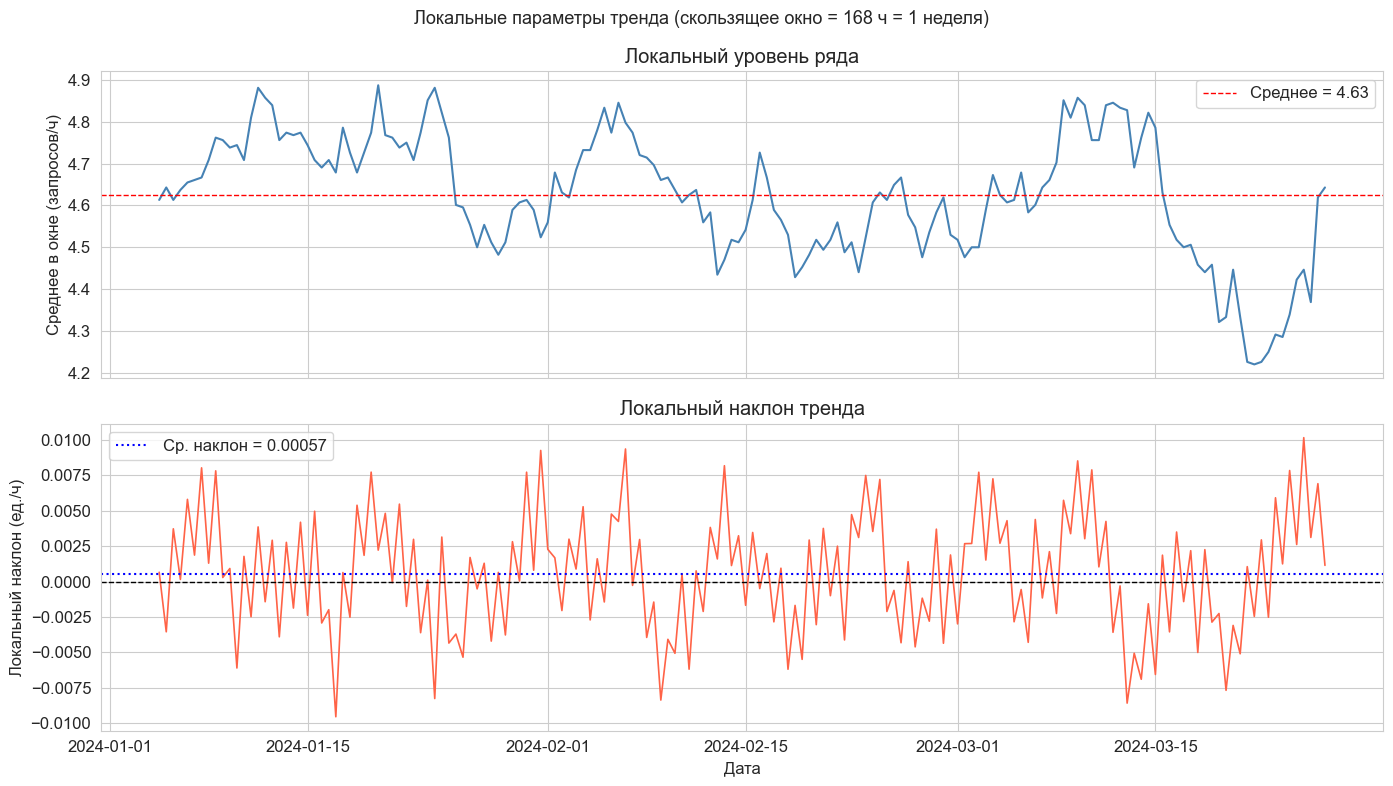

In [13]:
# График локальных параметров тренда
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle('Локальные параметры тренда (скользящее окно = 168 ч = 1 неделя)', fontsize=13)

axes[0].plot(local_times, local_means, color='steelblue', linewidth=1.5)
axes[0].axhline(local_means.mean(), color='red', linestyle='--',
                linewidth=1, label=f'Среднее = {local_means.mean():.2f}')
axes[0].set_ylabel('Среднее в окне (запросов/ч)')
axes[0].set_title('Локальный уровень ряда')
axes[0].legend()

axes[1].plot(local_times, local_slopes, color='tomato', linewidth=1.2)
axes[1].axhline(0, color='black', linewidth=1, linestyle='--')
axes[1].axhline(local_slopes.mean(), color='blue', linestyle=':',
                linewidth=1.5, label=f'Ср. наклон = {local_slopes.mean():.5f}')
axes[1].set_xlabel('Дата')
axes[1].set_ylabel('Локальный наклон (ед./ч)')
axes[1].set_title('Локальный наклон тренда')
axes[1].legend()

plt.tight_layout()
plt.show()

In [14]:
# Примеры уравнений локальных трендов (3 временных среза)
print('=== Примеры уравнений локальных трендов ===')
print()
example_indices = [0, len(local_slopes)//2, len(local_slopes)-1]
for i in example_indices:
    t_center = local_times[i]
    a = local_slopes[i]
    b = local_intercepts[i]
    sign = '+' if b >= 0 else '-'
    print(f'Окно с центром {t_center.date()}:')
    print(f'  y(τ) = {a:.5f}·τ {sign} {abs(b):.2f}')
    print(f'  Изменение за сутки (24 ч): {a*24:+.3f} запросов/ч')
    print()

print('Интерпретация: наклоны малы по модулю (< 0.01 запросов/ч²)')
print('→ локальные тренды неустойчивы и флуктуируют около нуля.')
print('→ ряд стационарен по уровню; доминирующая структура — суточная сезонность.')

=== Примеры уравнений локальных трендов ===

Окно с центром 2024-01-04:
  y(τ) = 0.00066·τ + 4.56
  Изменение за сутки (24 ч): +0.016 запросов/ч

Окно с центром 2024-02-15:
  y(τ) = -0.00168·τ + 4.68
  Изменение за сутки (24 ч): -0.040 запросов/ч

Окно с центром 2024-03-27:
  y(τ) = 0.00114·τ + 4.55
  Изменение за сутки (24 ч): +0.027 запросов/ч

Интерпретация: наклоны малы по модулю (< 0.01 запросов/ч²)
→ локальные тренды неустойчивы и флуктуируют около нуля.
→ ряд стационарен по уровню; доминирующая структура — суточная сезонность.


In [15]:
# Тест на стационарность: сравнение дисперсии в разных частях ряда
n_parts = 4
part_size = len(ts_vals) // n_parts
parts = [ts_vals[i*part_size:(i+1)*part_size] for i in range(n_parts)]

print('Анализ стационарности (разбивка на 4 части):')
print(f'{"Часть":<10} {"Период":<25} {"Среднее":>10} {"Ст.откл.":>10}')
for i, part in enumerate(parts):
    start_dt = ts.index[i*part_size].date()
    end_dt   = ts.index[min((i+1)*part_size-1, len(ts.index)-1)].date()
    print(f'{i+1:<10} {str(start_dt)+" — "+str(end_dt):<25} {part.mean():>10.3f} {part.std():>10.3f}')

# Тест Левена на равенство дисперсий
stat_lev, p_lev = stats.levene(*parts)
print(f'\nТест Левена на гомогенность дисперсий: stat={stat_lev:.4f}, p={p_lev:.4f}')
if p_lev > 0.05:
    print('p > 0.05 → дисперсия стационарна по частям (гомоскедастичность не отвергается).')
else:
    print('p < 0.05 → дисперсия меняется во времени (гетероскедастичность).')

Анализ стационарности (разбивка на 4 части):
Часть      Период                       Среднее   Ст.откл.
1          2024-01-01 — 2024-01-23        4.744      4.168
2          2024-01-23 — 2024-02-14        4.633      3.944
3          2024-02-15 — 2024-03-08        4.533      4.011
4          2024-03-08 — 2024-03-30        4.607      4.019

Тест Левена на гомогенность дисперсий: stat=0.6563, p=0.5790
p > 0.05 → дисперсия стационарна по частям (гомоскедастичность не отвергается).


---
## 5.5. Резюме и сравнительный анализ

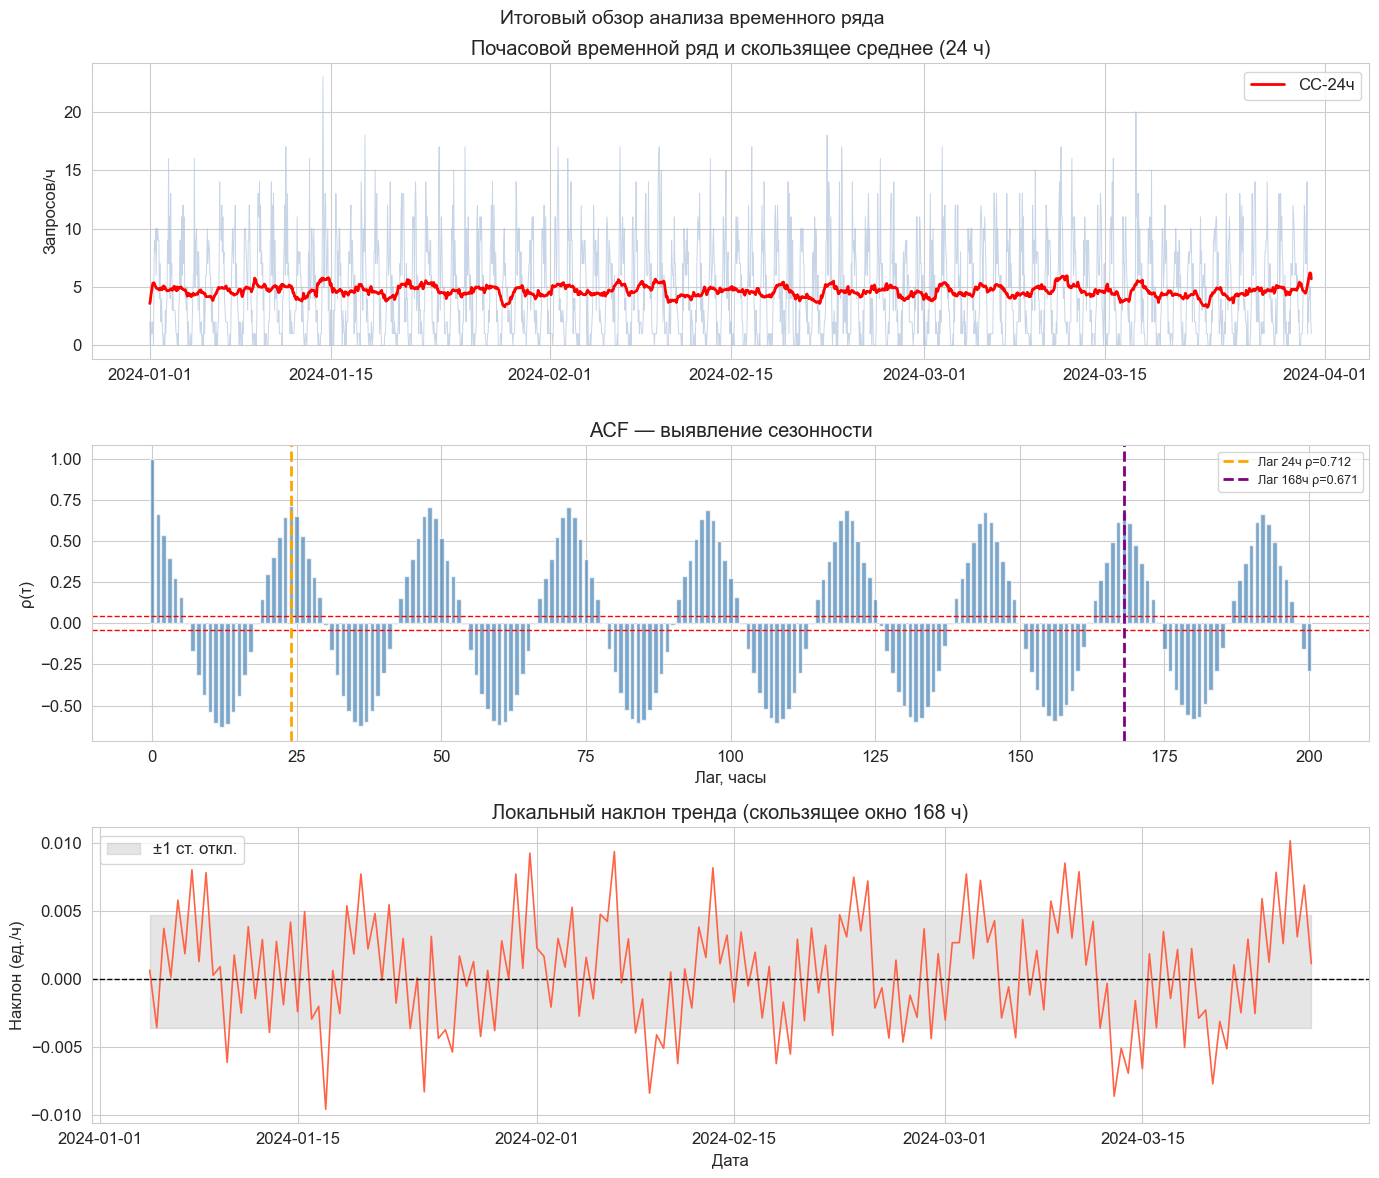

In [16]:
# Итоговый обзорный график
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)
fig.suptitle('Итоговый обзор анализа временного ряда', fontsize=14)

# 1. Исходный ряд + скользящее среднее 24ч
ma24 = pd.Series(ts_vals).rolling(24, center=True, min_periods=12).mean()
axes[0].plot(ts.index, ts_vals, color='lightsteelblue', linewidth=0.7, alpha=0.7)
axes[0].plot(ts.index, ma24.values, color='red', linewidth=2, label='СС-24ч')
axes[0].set_ylabel('Запросов/ч')
axes[0].set_title('Почасовой временной ряд и скользящее среднее (24 ч)')
axes[0].legend()

# 2. ACF (первые 200 лагов)
axes[1].bar(np.arange(MAX_LAG+1), ac, width=0.8, color='steelblue', alpha=0.7)
axes[1].axhline(ci_95, color='red', linestyle='--', linewidth=1)
axes[1].axhline(-ci_95, color='red', linestyle='--', linewidth=1)
for lag, col in zip([24, 168], ['orange', 'purple']):
    if lag <= MAX_LAG:
        axes[1].axvline(lag, color=col, linewidth=2, linestyle='--',
                        label=f'Лаг {lag}ч ρ={ac[lag]:.3f}')
axes[1].set_xlabel('Лаг, часы')
axes[1].set_ylabel('ρ(τ)')
axes[1].set_title('ACF — выявление сезонности')
axes[1].legend(fontsize=9)

# 3. Локальный наклон
axes[2].plot(local_times, local_slopes, color='tomato', linewidth=1.2)
axes[2].axhline(0, color='black', linewidth=1, linestyle='--')
axes[2].fill_between(local_times,
                     local_slopes.mean() - local_slopes.std(),
                     local_slopes.mean() + local_slopes.std(),
                     alpha=0.2, color='gray', label='±1 ст. откл.')
axes[2].set_xlabel('Дата')
axes[2].set_ylabel('Наклон (ед./ч)')
axes[2].set_title('Локальный наклон тренда (скользящее окно 168 ч)')
axes[2].legend()

plt.tight_layout()
plt.show()

In [17]:
# Итоговая сводная таблица результатов
print('=' * 60)
print('ИТОГИ ПРАКТИЧЕСКОЙ РАБОТЫ №5')
print('=' * 60)

print('\n1. ТЕХНИЧЕСКИЙ АНАЛИЗ')
if s_res is not None and s_sup is not None:
    print(f'   Линия сопротивления: y = {s_res:.4f}·t + {i_res:.1f}')
    print(f'   Линия поддержки:     y = {s_sup:.4f}·t + {i_sup:.1f}')
    print(f'   Ширина канала: {abs(i_res - i_sup):.1f} запросов/день')
    print(f'   Наклоны малы → горизонтальный (боковой) ценовой канал')

print('\n2. ТРЕНДОВЫЙ АНАЛИЗ')
for r in results_trend:
    print(f'   {r["Модель"]:<20}: R²={r["R²"]:+.4f}, RMSE={r["RMSE"]:.2f}')
print('   Вывод: R² < 0.02 — тренд статистически незначим.')

print('\n3. КОЛЕБАТЕЛЬНАЯ СТРУКТУРА')
print(f'   ρ(24ч)  = {ac[24]:.4f}  — суточный цикл (доминирует)')
if MAX_LAG >= 168:
    print(f'   ρ(168ч) = {ac[168]:.4f}  — недельный цикл')
print(f'   Главный период Фурье ≈ 24 ч')
print('   Пропорции: 24 : 48 : 72 : 168 = 1 : 2 : 3 : 7')

print('\n4. СКОЛЬЗЯЩЕЕ ОКНО (w=168ч)')
print(f'   Локальный наклон: {local_slopes.mean():.5f} ± {local_slopes.std():.5f} (≈ 0)')
print(f'   Локальный уровень: {local_means.mean():.2f} ± {local_means.std():.2f}')
print('   Вывод: ряд стационарен по уровню и дисперсии.')

print('\n5. ВЫБОР ПРЕДПОЧТИТЕЛЬНЫХ МЕТОДОВ:')
print('   ✓ Суточная сезонность наиболее надёжно выявляется через ACF и спектр Фурье.')
print('   ✓ Скользящее среднее с окном 24ч — лучший фильтр для визуализации уровня.')
print('   ✗ Трендовые модели (линейная, экспон., логист.) неинформативны для этих данных.')
print('   ✗ Технический анализ субъективен; линии поддержки чувствительны к выбору экстремумов.')
print('\n   Рекомендация для прогнозирования: сезонная модель')
print('   ŷ(t) = y(t - 24)  ("в этот час вчера") — простой и эффективный прогноз.')

ИТОГИ ПРАКТИЧЕСКОЙ РАБОТЫ №5

1. ТЕХНИЧЕСКИЙ АНАЛИЗ
   Линия сопротивления: y = 0.0259·t + 123.9
   Линия поддержки:     y = 0.0246·t + 94.0
   Ширина канала: 29.8 запросов/день
   Наклоны малы → горизонтальный (боковой) ценовой канал

2. ТРЕНДОВЫЙ АНАЛИЗ
   Линейный            : R²=+0.0183, RMSE=10.73
   Степенной           : R²=+0.0148, RMSE=10.75
   Экспоненциальный    : R²=+0.0184, RMSE=10.73
   Логистический       : R²=+0.0184, RMSE=10.73
   Вывод: R² < 0.02 — тренд статистически незначим.

3. КОЛЕБАТЕЛЬНАЯ СТРУКТУРА
   ρ(24ч)  = 0.7123  — суточный цикл (доминирует)
   ρ(168ч) = 0.6715  — недельный цикл
   Главный период Фурье ≈ 24 ч
   Пропорции: 24 : 48 : 72 : 168 = 1 : 2 : 3 : 7

4. СКОЛЬЗЯЩЕЕ ОКНО (w=168ч)
   Локальный наклон: 0.00057 ± 0.00416 (≈ 0)
   Локальный уровень: 4.63 ± 0.15
   Вывод: ряд стационарен по уровню и дисперсии.

5. ВЫБОР ПРЕДПОЧТИТЕЛЬНЫХ МЕТОДОВ:
   ✓ Суточная сезонность наиболее надёжно выявляется через ACF и спектр Фурье.
   ✓ Скользящее среднее с окном 